In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

import tensorflow as tf

## #11 KL-Divergence

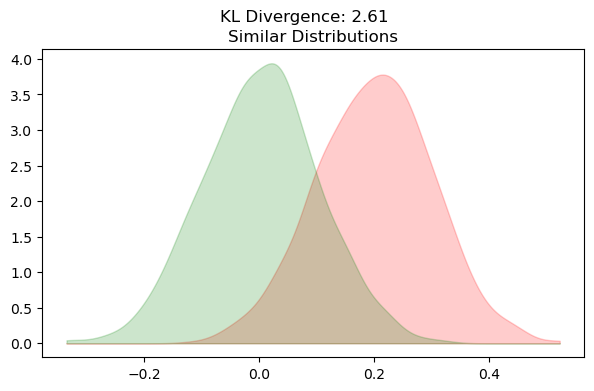

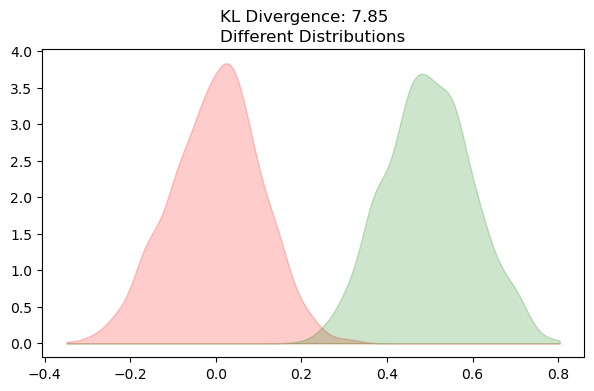

In [2]:
def KL(P, Q):
    epsilon = 0.00001
    P = P + epsilon
    Q = Q + epsilon
    divergence = np.sum(P * np.log(P / Q))
    return divergence

def generate_samples(mu, sigma):
    return np.random.normal(mu, sigma, 1000)

def calculate_distribution(s1, s2):
    bins = np.linspace(min(s1.min(), s2.min()), max(s1.max(), s2.max()), 100)
    p1, _ = np.histogram(s1, bins=bins, density=True)
    p2, _ = np.histogram(s2, bins=bins, density=True)
    p1 /= np.sum(p1)
    p2 /= np.sum(p2)
    return p1, p2, bins

def plot_distributions(s1, s2, bins, kl_div, dist1_label, dist2_label, title):
    plt.figure(figsize=(7, 4))
    plt.suptitle(f'KL Divergence: {kl_div:.2f}')

    density1 = gaussian_kde(s1)
    density2 = gaussian_kde(s2)
    x = np.linspace(min(s1.min(), s2.min()), max(s1.max(), s2.max()), 1000)

    plt.fill_between(x, density1(x), color='red', alpha=0.2, label=dist1_label)
    plt.fill_between(x, density2(x), color='green', alpha=0.2, label=dist2_label)
    plt.title(title)
    plt.show()

# Define two sets of observations
s1 = generate_samples(0.2, 0.1)
s2 = generate_samples(0, 0.1)

# Calculate distributions and KL divergence
p1, p2, bins = calculate_distribution(s1, s2)
kl_div = KL(p1, p2)

# Plot distributions
plot_distributions(s1, s2, bins, kl_div, 'Distribution 1', 'Distribution 2', 'Similar Distributions')

# Define two sets of observations
s3 = generate_samples(0.0, 0.1)
s4 = generate_samples(0.5, 0.1)

# Calculate distributions and KL divergence
p3, p4, bins = calculate_distribution(s3, s4)
kl_div = KL(p3, p4)

# Plot distributions
plot_distributions(s3, s4, bins, kl_div, 'Distribution 3', 'Distribution 4', 'Different Distributions')

## #12 Binary Classification

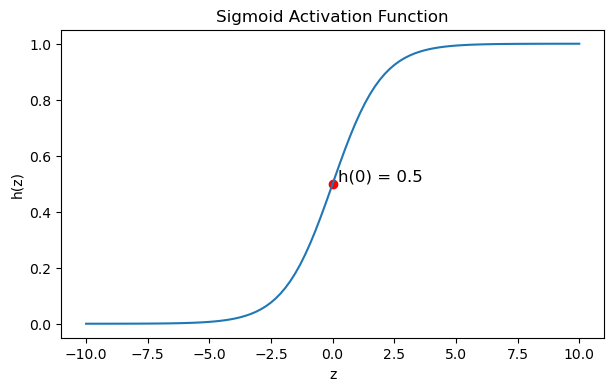

In [3]:
def sigmoid(z):
    """sigmoid activation function."""
    return 1 / (1 + np.exp(-z))

def plot_sigmoid():
    """plot the sigmoid activation function"""
    z = np.linspace(-10, 10, 100)
    h = sigmoid(z)

    plt.figure(figsize=(7, 4))
    plt.plot(z, h)
    plt.scatter([0], [0.5], color='red')
    plt.text(0.2, 0.5, 'h(0) = 0.5', fontsize=12, verticalalignment='bottom')
    plt.title('Sigmoid Activation Function')
    plt.xlabel('z')
    plt.ylabel('h(z)')
    plt.show()

plot_sigmoid()

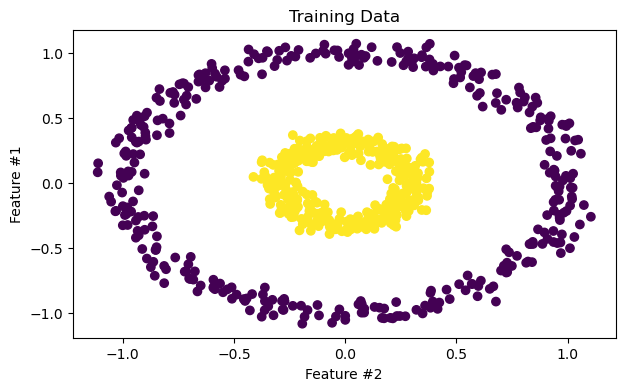

In [4]:
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split

def generate_data():
    """Generate a dataset of circles"""
    X, y = make_circles(n_samples=1000, factor=0.3, noise=0.05, random_state=0)
    return X, y

def split_data(X, y):
    """Split the dataset into training and testing sets."""
    X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=0)
    return X_train, X_test, y_train, y_test

def plot_data(X_train, y_train):
    """Plot the training data."""
    plt.figure(figsize=(7, 4))
    plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train)
    plt.ylabel('Feature #1')
    plt.xlabel('Feature #2')
    plt.title('Training Data')
    plt.show()

# Generate and split the data
X, y = generate_data()
X_train, X_test, y_train, y_test = split_data(X, y)
plot_data(X_train, y_train)

In [5]:
# import tensorflow as tf

# 1. model
model = tf.keras.models.Sequential(
    [
        tf.keras.layers.Dense(32, activation='relu', input_shape=(2,)),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid'),
    ]
)

# 2. compile
model.compile(optimizer=tf.keras.optimizers.Adam(), loss=tf.keras.losses.BinaryCrossentropy(), metrics=['accuracy'])

# 3. fit
model.fit(X_train, y_train, epochs=10, validation_data=(X_test, y_test))

Epoch 1/10
24/24 [==============================] - 3s 34ms/step - loss: 0.6489 - accuracy: 0.5120 - val_loss: 0.6284 - val_accuracy: 0.5000
Epoch 2/10
24/24 [==============================] - 0s 7ms/step - loss: 0.6030 - accuracy: 0.5000 - val_loss: 0.5790 - val_accuracy: 0.5040
Epoch 3/10
24/24 [==============================] - 0s 6ms/step - loss: 0.5493 - accuracy: 0.5840 - val_loss: 0.5180 - val_accuracy: 0.7440
Epoch 4/10
24/24 [==============================] - 0s 6ms/step - loss: 0.4832 - accuracy: 0.8280 - val_loss: 0.4434 - val_accuracy: 0.9680
Epoch 5/10
24/24 [==============================] - 0s 7ms/step - loss: 0.4095 - accuracy: 0.9840 - val_loss: 0.3706 - val_accuracy: 0.9840
Epoch 6/10
24/24 [==============================] - 0s 6ms/step - loss: 0.3406 - accuracy: 1.0000 - val_loss: 0.3049 - val_accuracy: 1.0000
Epoch 7/10
24/24 [==============================] - 0s 7ms/step - loss: 0.2758 - accuracy: 1.0000 - val_loss: 0.2420 - val_accuracy: 1.0000
Epoch 8/10
24/24 [=

In [6]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 32)                96        
                                                                 
 dense_1 (Dense)             (None, 32)                1056      
                                                                 
 dense_2 (Dense)             (None, 1)                 33        
                                                                 
Total params: 1,185
Trainable params: 1,185
Non-trainable params: 0
_________________________________________________________________


313/313 [==============================] - 1s 2ms/step


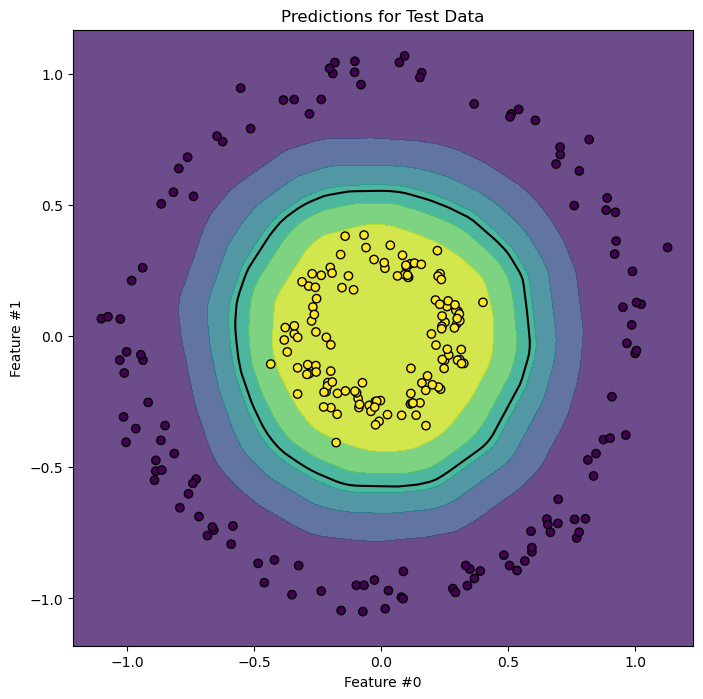

In [7]:
def create_grid(X):
    """Create a grid of points."""
    x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
    y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100),
                         np.linspace(y_min, y_max, 100))
    return xx, yy

def predict_grid(model, xx, yy):
    """Use the model to predict the grid points."""
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    return Z

def plot_predictions(xx, yy, Z, X_test, y_test):
    """Plot the contour of predictions and the test data."""
    plt.figure(figsize=(8, 8))
    plt.contourf(xx, yy, Z, alpha=0.8)
    plt.contour(xx, yy, Z, levels=[0.5], colors='k')  # Add decision boundary
    plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, edgecolors='k')
    plt.ylabel("Feature #1")
    plt.xlabel("Feature #0")
    plt.title("Predictions for Test Data")
    plt.show()

# Create a grid of points
xx, yy = create_grid(X)

# Use the model to predict the grid points
Z = predict_grid(model, xx, yy)

# Plot the contour of predictions and the test data
plot_predictions(xx, yy, Z, X_test, y_test)

## #13 Multi-Class Classification

In [3]:
def softmax(y):
    exps = np.exp(y)
    softmax_output = exps / np.sum(exps)
    return softmax_output

y = np.array([1.0, 2.0, 3.0])
softmax(y)

array([0.09003057, 0.24472847, 0.66524096])

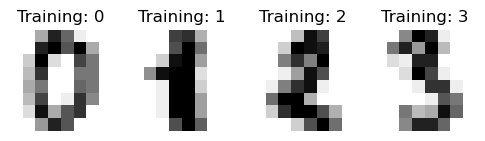

In [4]:
from sklearn import datasets
from sklearn.model_selection import train_test_split

digits = datasets.load_digits()

_, axes = plt.subplots(nrows=1, ncols=4, figsize=(6, 3))
for ax, image, label in zip(axes, digits.images, digits.target):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title('Training: %i' % label)

In [5]:
digits.images[0]

array([[ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.],
       [ 0.,  0., 13., 15., 10., 15.,  5.,  0.],
       [ 0.,  3., 15.,  2.,  0., 11.,  8.,  0.],
       [ 0.,  4., 12.,  0.,  0.,  8.,  8.,  0.],
       [ 0.,  5.,  8.,  0.,  0.,  9.,  8.,  0.],
       [ 0.,  4., 11.,  0.,  1., 12.,  7.,  0.],
       [ 0.,  2., 14.,  5., 10., 12.,  0.,  0.],
       [ 0.,  0.,  6., 13., 10.,  0.,  0.,  0.]])

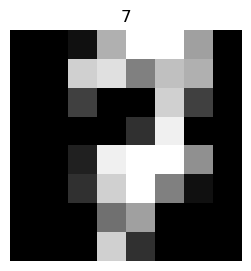

In [23]:
digit = 300
plt.figure(figsize=(6, 3))
plt.imshow(digits.images[digit], cmap='gray')
plt.title(digits.target[digit])
plt.axis('off')
plt.show()

In [10]:
# flatten the images
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))

# split data into 90% train and 10% test subsets
X_train, X_test, y_train, y_test = train_test_split(data, digits.target, test_size=0.1)

In [11]:
import tensorflow as tf

# 1. model
model = tf.keras.models.Sequential(
    [
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax'),
    ]
)

# 2. compile
model.compile(optimizer=tf.keras.optimizers.Adam(), loss=tf.keras.losses.SparseCategoricalCrossentropy(), metrics=['accuracy'])

# 3. fit
history = model.fit(X_train, y_train, epochs=10, validation_data=(X_test, y_test))

loss, accuracy = model.evaluate(X_test, y_test)
accuracy

Epoch 1/10
51/51 [==============================] - 2s 13ms/step - loss: 1.1900 - accuracy: 0.6376 - val_loss: 0.3820 - val_accuracy: 0.8778
Epoch 2/10
51/51 [==============================] - 0s 6ms/step - loss: 0.2365 - accuracy: 0.9252 - val_loss: 0.2307 - val_accuracy: 0.9222
Epoch 3/10
51/51 [==============================] - 0s 5ms/step - loss: 0.1394 - accuracy: 0.9617 - val_loss: 0.2184 - val_accuracy: 0.9500
Epoch 4/10
51/51 [==============================] - 0s 5ms/step - loss: 0.0879 - accuracy: 0.9777 - val_loss: 0.1633 - val_accuracy: 0.9444
Epoch 5/10
51/51 [==============================] - 0s 5ms/step - loss: 0.0627 - accuracy: 0.9864 - val_loss: 0.1687 - val_accuracy: 0.9556
Epoch 6/10
51/51 [==============================] - 0s 5ms/step - loss: 0.0423 - accuracy: 0.9913 - val_loss: 0.1091 - val_accuracy: 0.9667
Epoch 7/10
51/51 [==============================] - 0s 5ms/step - loss: 0.0374 - accuracy: 0.9932 - val_loss: 0.1120 - val_accuracy: 0.9611
Epoch 8/10
51/51 [=

0.9666666388511658

6/6 [==============================] - 0s 3ms/step


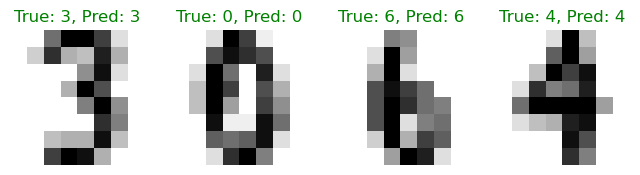

In [12]:
# predict the probabilities for each class
y_probs = model.predict(X_test)

# Get the class with the highest probability for each sample
y_pred = np.argmax(y_probs, axis=-1)

# Select four random indices from the test set
indices = np.random.choice(len(X_test), size=4, replace=False)

# Plot the images with the actual and predicted labels
_, axes = plt.subplots(nrows=1, ncols=4, figsize=(8, 4))
for ax, image, true_label, pred_label in zip(axes, X_test[indices].reshape(-1, 8, 8), y_test[indices], y_pred[indices]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    title = f'True: {true_label}, Pred: {pred_label}'
    ax.set_title(title, color='green' if true_label == pred_label else 'red')

## #14 Gradient Descent

In [13]:
import tensorflow as tf

x = tf.constant([0.03, 0.19, 0.34, 0.46, 0.78, 0.81, 1.08, 1.18, 1.39, 1.60, 1.65, 1.90], dtype=tf.float64)
y = tf.constant([0.67, 0.85, 1.05, 1.0, 1.40, 1.5, 1.3, 1.54, 1.55, 1.68, 1.73, 1.6 ], dtype=tf.float64)

def compute_loss(x, y, phi0, phi1):
    # Compute the predicted values
    y_pred = phi0 + phi1 * x
    # Compute the squared differences
    squared_diffs = tf.square(y_pred - y)
    # Return the sum of the squared differences
    return tf.reduce_sum(squared_diffs)

compute_loss(x, y, 0.0, 1)

<tf.Tensor: shape=(), dtype=float64, numpy=2.8077999999999994>

In [14]:
def compute_gradients(x, y, phi0, phi1):
    # Compute the predicted values
    y_pred = phi0 + phi1 * x
    # Compute the derivatives of the loss with respect to phi0 and phi1
    d_phi0 = -2 * tf.reduce_sum(y - y_pred)
    d_phi1 = -2 * tf.reduce_sum((y - y_pred) * x)
    return d_phi0, d_phi1

def update_parameters(phi0, phi1, d_phi0, d_phi1, learning_rate):
    # Update phi0 and phi1
    phi0 = phi0 - learning_rate * d_phi0
    phi1 = phi1 - learning_rate * d_phi1
    return phi0, phi1

def gradient_descent(x, y, phi0, phi1, learning_rate, num_iterations):
    # Sort the values of phi0, phi1, and the loss at each step
    phi0_values = [phi0]
    phi1_values = [phi1]
    loss_values = [compute_loss(x, y, phi0, phi1)]

    # Perform gradient descent
    for i in range(num_iterations):
        # step 1: Compute the gradients
        d_phi0, d_phi1 = compute_gradients(x, y, phi0, phi1)

        # step 2: Update phi0 and phi1 using the gradients
        phi0, phi1 = update_parameters(phi0, phi1, d_phi0, d_phi1, learning_rate)

        # step 3: Store the new values of phi0, phi1, and the loss
        phi0_values.append(phi0)
        phi1_values.append(phi1)
        loss_values.append(compute_loss(x, y, phi0, phi1))

    return phi0, phi1, phi0_values, phi1_values, loss_values

# Define the learning rate and the number of iterations
learning_rate = 0.003
num_iterations = 100

# Initialize phi0 and phi1
phi0, phi1 = 0.1, 0.1

# Perform gradient descent
phi0, phi1, phi0_values, phi1_values, loss_values = gradient_descent(x, y, phi0, phi1, learning_rate, num_iterations)

f'Final phi0: {phi0:.4f}, Final phi1: {phi1:.4f}'

'Final phi0: 0.7657, Final phi1: 0.5751'

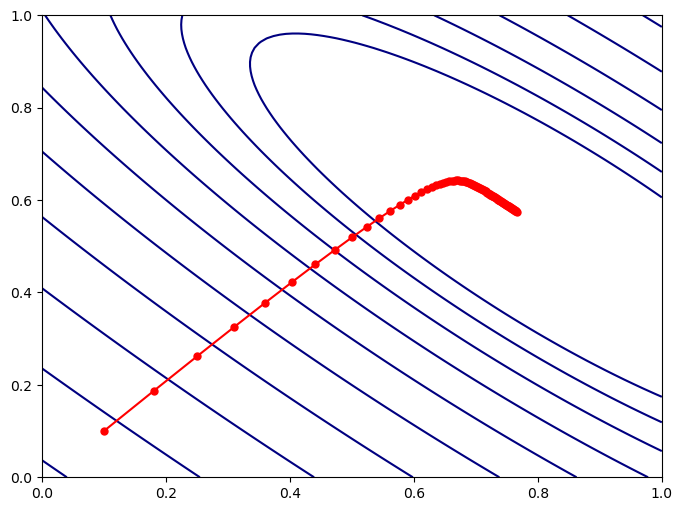

In [15]:
# Create a grid of phi0 and phi1 values
phi0_grid = np.linspace(0, 1, 100)
phi1_grid = np.linspace(0, 1, 100)
phi0_grid, phi1_grid = np.meshgrid(phi0_grid, phi1_grid)

# Compute the loss for each pair of phi0 and phi1 values
loss_grid = np.zeros_like(phi0_grid)
for i in range(phi0_grid.shape[0]):
    for j in range(phi0_grid.shape[1]):
        loss_grid[i, j] = compute_loss(x, y, phi0_grid[i, j], phi1_grid[i, j])

# Create a contour plot of the loss
plt.figure(figsize=(8, 6))
plt.contour(phi0_grid, phi1_grid, loss_grid, levels=np.logspace(0, 5, 35), cmap='jet')

# Plot the path of the gradient descent points
plt.plot(phi0_values, phi1_values, 'r', marker='o', markersize=5)

# Show the plot
plt.show()

## #15 SGD

In [16]:
# Data
x = tf.constant([0.03, 0.19, 0.34, 0.46, 0.78, 0.81, 1.08, 1.18, 1.39, 1.60, 1.65, 1.90])
y = tf.constant([0.67, 0.85, 1.05, 1.0, 1.40, 1.5, 1.3, 1.54, 1.55, 1.68, 1.73, 1.6 ])

# Model
model = tf.keras.Sequential(
    [
        tf.keras.layers.Dense(1, input_shape=(1, ))
    ]
)

# Compile
model.compile(loss=tf.keras.losses.MeanSquaredError(), optimizer=tf.keras.optimizers.SGD())

# Train
model.fit(x, y, epochs=30, batch_size=3)

Epoch 1/30
4/4 [==============================] - 1s 5ms/step - loss: 0.2105
Epoch 2/30
4/4 [==============================] - 0s 4ms/step - loss: 0.2068
Epoch 3/30
4/4 [==============================] - 0s 4ms/step - loss: 0.2012
Epoch 4/30
4/4 [==============================] - 0s 4ms/step - loss: 0.1952
Epoch 5/30
4/4 [==============================] - 0s 4ms/step - loss: 0.1903
Epoch 6/30
4/4 [==============================] - 0s 3ms/step - loss: 0.1862
Epoch 7/30
4/4 [==============================] - 0s 4ms/step - loss: 0.1825
Epoch 8/30
4/4 [==============================] - 0s 3ms/step - loss: 0.1778
Epoch 9/30
4/4 [==============================] - 0s 3ms/step - loss: 0.1720
Epoch 10/30
4/4 [==============================] - 0s 4ms/step - loss: 0.1684
Epoch 11/30
4/4 [==============================] - 0s 4ms/step - loss: 0.1658
Epoch 12/30
4/4 [==============================] - 0s 3ms/step - loss: 0.1616
Epoch 13/30
4/4 [==============================] - 0s 3ms/step - loss: 0.

1/1 [==============================] - 0s 89ms/step


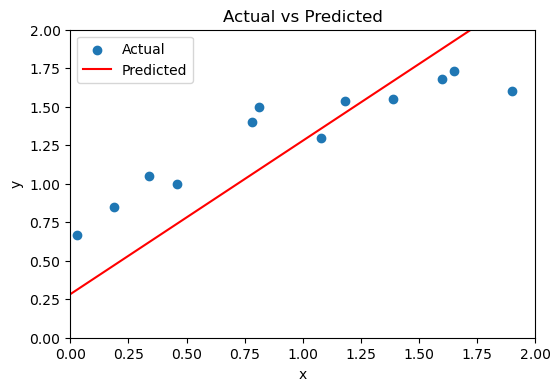

(<matplotlib.legend.Legend at 0x1d7f9b8f490>, None)

In [17]:
# Predict
x_values = np.linspace(0, 2, 10)
y_pred = model.predict(x_values)

# Plot
plt.figure(figsize=(6, 4))
plt.scatter(x, y, label='Actual')
plt.plot(x_values, y_pred, c='red', label='Predicted')
plt.xlim([0, 2]); plt.ylim([0, 2])
plt.xlabel('x'); plt.ylabel('y')
plt.title('Actual vs Predicted')
plt.legend(), plt.show()